In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch

from rl4co.envs import CVRPEnv
from rl4co.models.zoo.decomposition import DECOMP, KmeansPol, BaryCenterDecomp, Delegate
from rl4co.models.zoo.am import AttentionModelPolicy

/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


In [53]:
# torch.manual_seed(42)

env = CVRPEnv(generator_params={'num_loc': 40})
model = DECOMP(env,
                baseline='rollout',
                train_data_size=1_000,
                val_data_size=100)

/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'env' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['env'])`.
/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'policy' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['policy'])`.
/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'decomp_pol' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['decomp_pol'])`.
/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:199: A

In [58]:
td = env.reset(batch_size=[4])
td_old = td.clone()
out = model.naive_pol(td, env, return_actions=True)

In [61]:
td_old

TensorDict(
    fields={
        action_mask: Tensor(shape=torch.Size([4, 41]), device=cpu, dtype=torch.bool, is_shared=False),
        capacity: Tensor(shape=torch.Size([4, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        current_node: Tensor(shape=torch.Size([4, 1]), device=cpu, dtype=torch.int64, is_shared=False),
        demand: Tensor(shape=torch.Size([4, 40]), device=cpu, dtype=torch.float32, is_shared=False),
        depot: Tensor(shape=torch.Size([4, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        done: Tensor(shape=torch.Size([4, 1]), device=cpu, dtype=torch.bool, is_shared=False),
        locs: Tensor(shape=torch.Size([4, 41, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        terminated: Tensor(shape=torch.Size([4, 1]), device=cpu, dtype=torch.bool, is_shared=False),
        used_capacity: Tensor(shape=torch.Size([4, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        vehicle_capacity: Tensor(shape=torch.Size([4, 1]), de

In [4]:
def render_all(td, out, env):
    for td, actions in zip(td, out['actions'].cpu()):
        env.render(td, actions)

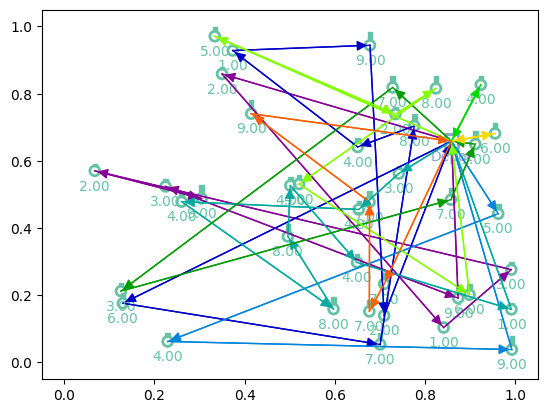

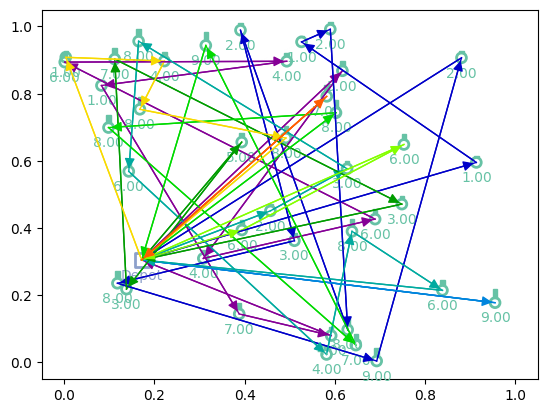

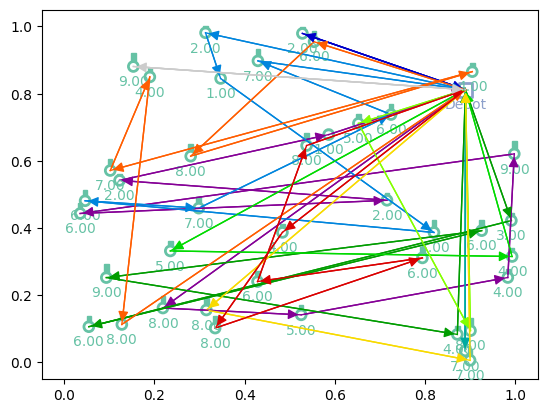

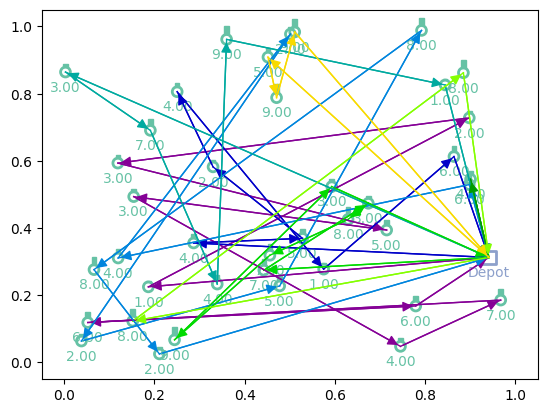

In [55]:
td = env.reset(batch_size=[4])
out = model.naive_pol(td, env, return_actions=True)
render_all(td, out, env)

In [65]:
model.decomp_pol = BaryCenterDecomp(4)

In [66]:
td_new = model.decomp_pol(td, env, out)

In [71]:
td_old

TensorDict(
    fields={
        action_mask: Tensor(shape=torch.Size([4, 41]), device=cpu, dtype=torch.bool, is_shared=False),
        capacity: Tensor(shape=torch.Size([4, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        current_node: Tensor(shape=torch.Size([4, 1]), device=cpu, dtype=torch.int64, is_shared=False),
        demand: Tensor(shape=torch.Size([4, 40]), device=cpu, dtype=torch.float32, is_shared=False),
        depot: Tensor(shape=torch.Size([4, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        done: Tensor(shape=torch.Size([4, 1]), device=cpu, dtype=torch.bool, is_shared=False),
        locs: Tensor(shape=torch.Size([4, 41, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        terminated: Tensor(shape=torch.Size([4, 1]), device=cpu, dtype=torch.bool, is_shared=False),
        used_capacity: Tensor(shape=torch.Size([4, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        vehicle_capacity: Tensor(shape=torch.Size([4, 1]), de

In [73]:
td_new

TensorDict(
    fields={
        action_mask: Tensor(shape=torch.Size([16, 34]), device=cpu, dtype=torch.float32, is_shared=False),
        capacity: Tensor(shape=torch.Size([16, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        current_node: Tensor(shape=torch.Size([16, 1]), device=cpu, dtype=torch.int64, is_shared=False),
        demand: Tensor(shape=torch.Size([16, 33]), device=cpu, dtype=torch.float32, is_shared=False),
        depot: Tensor(shape=torch.Size([16, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        done: Tensor(shape=torch.Size([16, 1]), device=cpu, dtype=torch.bool, is_shared=False),
        locs: Tensor(shape=torch.Size([16, 34, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        reward: Tensor(shape=torch.Size([16, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        terminated: Tensor(shape=torch.Size([16, 1]), device=cpu, dtype=torch.bool, is_shared=False),
        used_capacity: Tensor(shape=torch.Size([16, 1]),

In [41]:
env = CVRPEnv(generator_params={'num_loc': 36})

The capacity capacity for 36 locations is not defined. Using the closest capacity: 37.0                    with 40 locations.


In [74]:
out = model.policy(td_new, env, return_actions=True)
render_all(td, out, env)

AssertionError: No logprobs were collected because all environments were done. Check your initial state